# Hoja de trabajo #2 — Transformers y mecanismos de atención
**CC3092 Deep Learning y Sistemas Inteligentes** · Javier Benítez (23405)

Contenido:
1. Ejercicio a mano de *scaled dot-product attention* (verificado con código)
2. Implementación desde cero (atención + multi-head) y verificaciones contra PyTorch
3. Escalamiento y costo computacional ($\sqrt{d_k}$, tiempo y memoria vs. $n$)
4. Visualización de atención en BERT y GPT-2 (mapas de calor, *it → animal/street*, máscara causal, *attention sinks*, entropía)

In [1]:
import math, time, tracemalloc
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import seaborn as sns
from transformers import AutoTokenizer, AutoModel

torch.manual_seed(0); np.random.seed(0)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9})
import os; os.makedirs("figs", exist_ok=True)
print(torch.__version__)

/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


2.14.1+cpu


## 1. Ejercicio a mano

Secuencia de 3 tokens con $d_k = 2$. Tomamos (para que las cuentas sean simples):

$$Q=\begin{pmatrix}1&0\\0&1\\1&1\end{pmatrix},\quad K=\begin{pmatrix}1&0\\0&1\\1&1\end{pmatrix},\quad V=\begin{pmatrix}1&0\\0&2\\1&1\end{pmatrix}$$

**Paso 1 — puntajes** $S = QK^\top$:
$$S=\begin{pmatrix}1&0&1\\0&1&1\\1&1&2\end{pmatrix}$$

**Paso 2 — escalar** por $\sqrt{2}\approx1.414$:
$$S/\sqrt{2}=\begin{pmatrix}0.707&0&0.707\\0&0.707&0.707\\0.707&0.707&1.414\end{pmatrix}$$

**Paso 3 — softmax por fila.** Fila 1: $e^{0.707}=2.028,\ e^0=1$ → suma $=5.056$ → $(0.401,\,0.198,\,0.401)$.
Fila 2 es la misma permutada: $(0.198,\,0.401,\,0.401)$.
Fila 3: $e^{0.707}=2.028$ (×2), $e^{1.414}=4.113$ → suma $=8.169$ → $(0.248,\,0.248,\,0.504)$.

**Paso 4 — salida** $A V$:
- fila 1: $0.401(1,0)+0.198(0,2)+0.401(1,1) = (0.802,\ 0.797)$
- fila 2: $0.198(1,0)+0.401(0,2)+0.401(1,1) = (0.599,\ 1.203)$
- fila 3: $0.248(1,0)+0.248(0,2)+0.504(1,1) = (0.752,\ 1.000)$

**Paso 5 — con máscara causal** (cada token sólo ve los anteriores): fila 1 → $(1,0,0)$; fila 2 → softmax$(0, 0.707)=(0.330, 0.670)$; fila 3 igual que sin máscara.
Salida: $(1,0)$, $(0.330,\,1.340)$, $(0.752,\,1.000)$.

In [2]:
Q = torch.tensor([[1.,0],[0,1],[1,1]]); K = Q.clone(); V = torch.tensor([[1.,0],[0,2],[1,1]])
S = Q @ K.T / math.sqrt(2)
A = S.softmax(-1)
print("Pesos A:\n", A.numpy().round(3)); print("Salida AV:\n", (A@V).numpy().round(3))
ref = F.scaled_dot_product_attention(Q[None], K[None], V[None])[0]
print("¿Coincide con F.scaled_dot_product_attention?", torch.allclose(A@V, ref, atol=1e-6))
ref_c = F.scaled_dot_product_attention(Q[None], K[None], V[None], is_causal=True)[0]
print("Salida causal:\n", ref_c.numpy().round(3))

Pesos A:
 [[0.401 0.198 0.401]
 [0.198 0.401 0.401]
 [0.248 0.248 0.503]]
Salida AV:
 [[0.802 0.797]
 [0.599 1.203]
 [0.752 1.   ]]
¿Coincide con F.scaled_dot_product_attention? True
Salida causal:
 [[1.    0.   ]
 [0.33  1.34 ]
 [0.752 1.   ]]


## 2. Implementación desde cero y verificaciones

Implementamos `attention()` y `MultiHeadAttention` sólo con operaciones de tensores y verificamos:
1. igualdad con `F.scaled_dot_product_attention` (con y sin máscara causal),
2. igualdad con `nn.MultiheadAttention` copiando los mismos pesos,
3. que cada fila de pesos suma 1 y que la máscara causal produce una matriz triangular inferior,
4. que el número de parámetros de multi-head no depende de $h$.

In [3]:
def attention(q, k, v, mask=None, causal=False, scale=None):
    """q:(...,n,d) k:(...,m,d) v:(...,m,dv). mask: bool, True = permitido."""
    d = q.size(-1)
    s = (q @ k.transpose(-2, -1)) * (scale if scale is not None else 1 / math.sqrt(d))
    if causal:
        n, m = s.shape[-2:]
        s = s.masked_fill(~torch.ones(n, m, dtype=torch.bool).tril(), float("-inf"))
    if mask is not None:
        s = s.masked_fill(~mask, float("-inf"))
    w = s.softmax(-1)
    return w @ v, w


class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, h):
        super().__init__()
        assert d_model % h == 0
        self.h, self.dk = h, d_model // h
        self.Wq, self.Wk, self.Wv, self.Wo = (nn.Linear(d_model, d_model) for _ in range(4))

    def split(self, x):                       # (B,n,d) -> (B,h,n,dk)
        B, n, _ = x.shape
        return x.view(B, n, self.h, self.dk).transpose(1, 2)

    def forward(self, x_q, x_kv=None, causal=False):
        x_kv = x_q if x_kv is None else x_kv      # self- vs cross-attention
        q, k, v = self.split(self.Wq(x_q)), self.split(self.Wk(x_kv)), self.split(self.Wv(x_kv))
        out, w = attention(q, k, v, causal=causal)
        B, _, n, _ = out.shape
        return self.Wo(out.transpose(1, 2).reshape(B, n, -1)), w

# --- Verificación 1: contra F.scaled_dot_product_attention
B, h, n, d = 2, 4, 10, 16
q, k, v = torch.randn(B, h, n, d), torch.randn(B, h, n, d), torch.randn(B, h, n, d)
for c in (False, True):
    mine, w = attention(q, k, v, causal=c)
    ref = F.scaled_dot_product_attention(q, k, v, is_causal=c)
    print(f"causal={c}: max |diff| = {(mine-ref).abs().max():.2e}")

# --- Verificación 3: filas suman 1 y triangular inferior
_, w = attention(q, k, v, causal=True)
print("Filas suman 1:", torch.allclose(w.sum(-1), torch.ones(B, h, n)))
print("Triangular inferior (triu estricta = 0):", w.triu(1).abs().max().item() == 0)

causal=False: max |diff| = 2.38e-07
causal=True: max |diff| = 2.38e-07
Filas suman 1: True
Triangular inferior (triu estricta = 0): True


In [4]:
# --- Verificación 2: contra nn.MultiheadAttention con los mismos pesos
d_model, H = 32, 4
mine = MultiHeadAttention(d_model, H)
ref = nn.MultiheadAttention(d_model, H, batch_first=True)
with torch.no_grad():
    ref.in_proj_weight.copy_(torch.cat([mine.Wq.weight, mine.Wk.weight, mine.Wv.weight]))
    ref.in_proj_bias.copy_(torch.cat([mine.Wq.bias, mine.Wk.bias, mine.Wv.bias]))
    ref.out_proj.weight.copy_(mine.Wo.weight); ref.out_proj.bias.copy_(mine.Wo.bias)

x = torch.randn(3, 7, d_model)
mask = nn.Transformer.generate_square_subsequent_mask(7)        # -inf arriba de la diagonal
o1, w1 = mine(x, causal=True)
o2, w2 = ref(x, x, x, attn_mask=mask, need_weights=True, average_attn_weights=False)
print("salida  max|diff|:", (o1 - o2).abs().max().item())
print("pesos   max|diff|:", (w1 - w2).abs().max().item())
print(mask)

# --- Verificación 4: parámetros vs número de cabezas
for hh in (1, 2, 4, 8):
    print(f"h={hh}: params = {sum(p.numel() for p in MultiHeadAttention(512, hh).parameters()):,}")

salida  max|diff|: 8.940696716308594e-08
pesos   max|diff|: 8.940696716308594e-08
tensor([[0., -inf, -inf, -inf, -inf, -inf, -inf],
        [0., 0., -inf, -inf, -inf, -inf, -inf],
        [0., 0., 0., -inf, -inf, -inf, -inf],
        [0., 0., 0., 0., -inf, -inf, -inf],
        [0., 0., 0., 0., 0., -inf, -inf],
        [0., 0., 0., 0., 0., 0., -inf],
        [0., 0., 0., 0., 0., 0., 0.]])
h=1: params = 1,050,624
h=2: params = 1,050,624
h=4: params = 1,050,624
h=8: params = 1,050,624


In [5]:
# Bloque encoder de PyTorch: Post-LN (norm_first=False, original) vs Pre-LN (norm_first=True)
for nf in (False, True):
    layer = nn.TransformerEncoderLayer(d_model=64, nhead=4, dim_feedforward=256, dropout=0.1,
                                       batch_first=True, norm_first=nf)
    y = layer(torch.randn(2, 5, 64))
    print(f"norm_first={nf}: salida {tuple(y.shape)}, params={sum(p.numel() for p in layer.parameters()):,}")

norm_first=False: salida (2, 5, 64), params=49,984
norm_first=True: salida (2, 5, 64), params=49,984


## 3. Escalamiento y costo computacional

**(a) ¿Por qué $\sqrt{d_k}$?** Si $q_i,k_i\sim(0,1)$ independientes, $q\cdot k=\sum_{i=1}^{d_k} q_ik_i$ tiene media 0 y varianza $d_k$. Lo comprobamos empíricamente y medimos cómo, sin escalar, la softmax se satura (entropía → 0, gradiente → 0).

d_k  -> Var(q·k): {4: np.float64(4.0), 16: np.float64(16.0), 64: np.float64(63.7), 256: np.float64(262.0), 1024: np.float64(1014.1)}


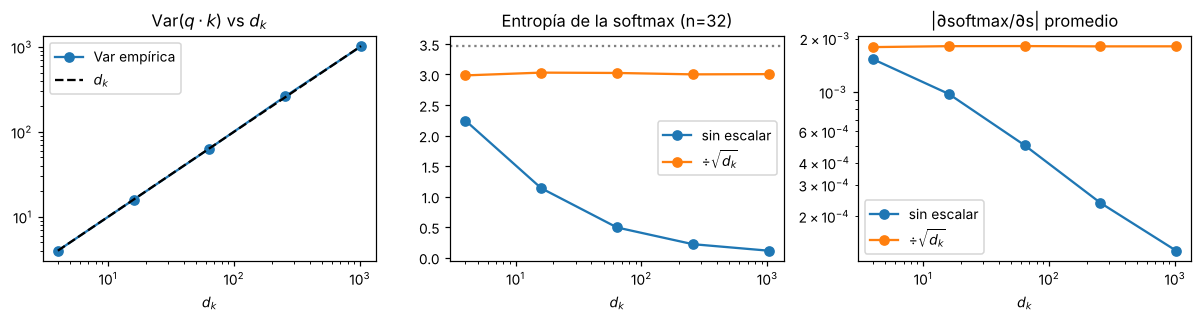

In [6]:
dks = [4, 16, 64, 256, 1024]
rows = []
for dk in dks:
    qq, kk = torch.randn(20000, dk), torch.randn(20000, dk)
    rows.append((qq * kk).sum(-1).var().item())
print("d_k  -> Var(q·k):", dict(zip(dks, np.round(rows, 1))))

def softmax_stats(dk, scaled, n=32, trials=200):
    ents, grads = [], []
    for _ in range(trials):
        qv = torch.randn(1, dk); kv = torch.randn(n, dk)
        s = (qv @ kv.T).squeeze(0)
        if scaled: s = s / math.sqrt(dk)
        s.requires_grad_(True)
        p = s.softmax(-1)
        ents.append(-(p * (p + 1e-12).log()).sum().item())
        J = torch.autograd.functional.jacobian(lambda z: z.softmax(-1), s.detach())
        grads.append(J.abs().mean().item())
    return np.mean(ents), np.mean(grads)

stats = {sc: [softmax_stats(dk, sc) for dk in dks] for sc in (False, True)}
fig, ax = plt.subplots(1, 3, figsize=(11, 3))
ax[0].loglog(dks, rows, "o-", label="Var empírica"); ax[0].loglog(dks, dks, "k--", label="$d_k$")
ax[0].set(title="Var($q\\cdot k$) vs $d_k$", xlabel="$d_k$"); ax[0].legend()
for sc, lab in ((False, "sin escalar"), (True, "÷$\\sqrt{d_k}$")):
    ax[1].semilogx(dks, [s[0] for s in stats[sc]], "o-", label=lab)
    ax[2].loglog(dks, [s[1] for s in stats[sc]], "o-", label=lab)
ax[1].axhline(math.log(32), ls=":", c="gray"); ax[1].set(title="Entropía de la softmax (n=32)", xlabel="$d_k$")
ax[2].set(title="|∂softmax/∂s| promedio", xlabel="$d_k$"); ax[1].legend(); ax[2].legend()
plt.tight_layout(); plt.savefig("figs/escalamiento_dk.png", bbox_inches="tight"); plt.show()

**(b) Costo vs. longitud $n$.** La matriz de atención es $n\times n$: tiempo $O(n^2 d)$ y memoria $O(n^2)$. Medimos tiempo (forward) y memoria pico de nuestra implementación explícita contra `F.scaled_dot_product_attention` (que en CPU puede usar un kernel fusionado tipo *flash/memory-efficient* que no materializa la matriz completa).

n=  128  naive=    0.21 ms   sdpa=    0.13 ms
n=  256  naive=    0.66 ms   sdpa=    0.41 ms
n=  512  naive=    3.86 ms   sdpa=    1.59 ms
n= 1024  naive=   33.39 ms   sdpa=    5.99 ms
n= 2048  naive=  107.79 ms   sdpa=   24.27 ms
n= 4096  naive=  377.55 ms   sdpa=  107.41 ms


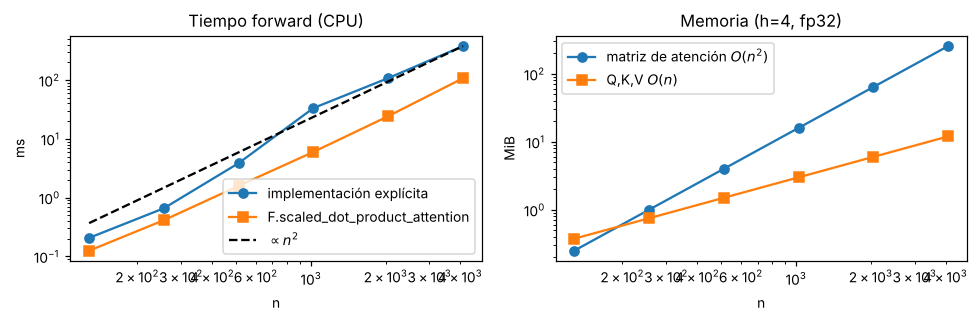

Extrapolación: n=100,000, 1 cabeza fp32 → 37.3 GiB sólo para la matriz de atención


In [7]:
def bench(fn, n, d=64, h=4, reps=3):
    q = torch.randn(1, h, n, d); k = torch.randn(1, h, n, d); v = torch.randn(1, h, n, d)
    fn(q, k, v)
    t0 = time.perf_counter()
    for _ in range(reps): fn(q, k, v)
    t = (time.perf_counter() - t0) / reps
    return t

naive = lambda q, k, v: attention(q, k, v)[0]
fused = lambda q, k, v: F.scaled_dot_product_attention(q, k, v)
ns = [128, 256, 512, 1024, 2048, 4096]
t_naive = [bench(naive, n) for n in ns]
t_fused = [bench(fused, n) for n in ns]
mem_matrix = [4 * 4 * n * n / 2**20 for n in ns]   # h=4 cabezas, float32, MiB de la matriz de atención
mem_qkv = [3 * 4 * 4 * n * 64 / 2**20 for n in ns]  # Q,K,V: lineal en n

for n, a, b in zip(ns, t_naive, t_fused): print(f"n={n:5d}  naive={a*1e3:8.2f} ms   sdpa={b*1e3:8.2f} ms")

fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].loglog(ns, np.array(t_naive) * 1e3, "o-", label="implementación explícita")
ax[0].loglog(ns, np.array(t_fused) * 1e3, "s-", label="F.scaled_dot_product_attention")
ref = np.array(ns, float) ** 2; ax[0].loglog(ns, ref / ref[-1] * t_naive[-1] * 1e3, "k--", label="$\\propto n^2$")
ax[0].set(title="Tiempo forward (CPU)", xlabel="n", ylabel="ms"); ax[0].legend()
ax[1].loglog(ns, mem_matrix, "o-", label="matriz de atención $O(n^2)$")
ax[1].loglog(ns, mem_qkv, "s-", label="Q,K,V $O(n)$")
ax[1].set(title="Memoria (h=4, fp32)", xlabel="n", ylabel="MiB"); ax[1].legend()
plt.tight_layout(); plt.savefig("figs/costo_n.png", bbox_inches="tight"); plt.show()
print(f"Extrapolación: n=100,000, 1 cabeza fp32 → {4*100_000**2/2**30:.1f} GiB sólo para la matriz de atención")

## 4. Atención en modelos preentrenados (BERT y GPT-2)

Ambos se cargan con `output_attentions=True` y `attn_implementation="eager"`. El modelo devuelve una tupla con **una matriz por capa** de forma `(batch, cabezas, n, n)`: 12 capas × 12 cabezas en ambos.

In [8]:
tok_bert = AutoTokenizer.from_pretrained("bert-base-uncased")
bert = AutoModel.from_pretrained("bert-base-uncased", output_attentions=True, attn_implementation="eager").eval()
tok_gpt2 = AutoTokenizer.from_pretrained("gpt2")
gpt2 = AutoModel.from_pretrained("gpt2", output_attentions=True, attn_implementation="eager").eval()

@torch.no_grad()
def get_att(model, tok, text):
    enc = tok(text, return_tensors="pt")
    att = torch.stack(model(**enc).attentions)[:, 0]     # (L, H, n, n)
    toks = [t.replace("Ġ", "·") for t in tok.convert_ids_to_tokens(enc["input_ids"][0])]
    return att, toks

sent = "The cat sat on the mat because it was tired."
att_b, toks_b = get_att(bert, tok_bert, sent)
att_g, toks_g = get_att(gpt2, tok_gpt2, sent)
print("BERT:", att_b.shape, toks_b); print("GPT-2:", att_g.shape, toks_g)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 6535.95it/s]


[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 8258.37it/s]

BERT: torch.Size([12, 12, 13, 13]) ['[CLS]', 'the', 'cat', 'sat', 'on', 'the', 'mat', 'because', 'it', 'was', 'tired', '.', '[SEP]']
GPT-2: torch.Size([12, 12, 11, 11]) ['The', '·cat', '·sat', '·on', '·the', '·mat', '·because', '·it', '·was', '·tired', '.']


### 4.1 Mapas de calor de 4 cabezas en capas distintas

In [9]:
def plot_heads(att, toks, heads, title, fname):
    fig, axes = plt.subplots(1, len(heads), figsize=(4.2 * len(heads), 3.8))
    for ax, (l, h, lab) in zip(axes, heads):
        sns.heatmap(att[l, h].numpy(), xticklabels=toks, yticklabels=toks, cmap="viridis",
                    vmin=0, vmax=1, cbar=False, ax=ax, square=True)
        ax.set_title(f"L{l} H{h}: {lab}", fontsize=9); ax.tick_params(labelsize=7)
        ax.set_xlabel("key (atendido)"); ax.set_ylabel("query")
    fig.suptitle(title); plt.tight_layout(); plt.savefig(fname, bbox_inches="tight"); plt.show()

# Diagnóstico automático: qué patrón domina en cada cabeza de BERT
def pattern_scores(att, toks):
    n = att.shape[-1]
    prev = att[..., torch.arange(1, n), torch.arange(0, n - 1)].mean(-1)
    nxt  = att[..., torch.arange(0, n - 1), torch.arange(1, n)].mean(-1)
    selfa = att.diagonal(dim1=-2, dim2=-1).mean(-1)
    cls = att[..., :, 0].mean(-1)
    sep = att[..., :, -1].mean(-1) if toks[-1] == "[SEP]" else torch.zeros_like(cls)
    punct = att[..., :, [i for i, t in enumerate(toks) if t in {".", ",", "·.", "·,"}]].sum(-1).mean(-1)
    return dict(prev=prev, next=nxt, self=selfa, cls=cls, sep=sep, punct=punct)

ps = pattern_scores(att_b, toks_b)
for k_, v_ in ps.items():
    l, h = divmod(v_.argmax().item(), 12); print(f"{k_:6s}: mejor cabeza L{l} H{h}  ({v_[l, h]:.2f})")

prev  : mejor cabeza L3 H5  (0.60)
next  : mejor cabeza L2 H9  (0.92)
self  : mejor cabeza L2 H6  (0.46)
cls   : mejor cabeza L1 H6  (0.94)
sep   : mejor cabeza L5 H1  (0.88)
punct : mejor cabeza L10 H1  (0.56)


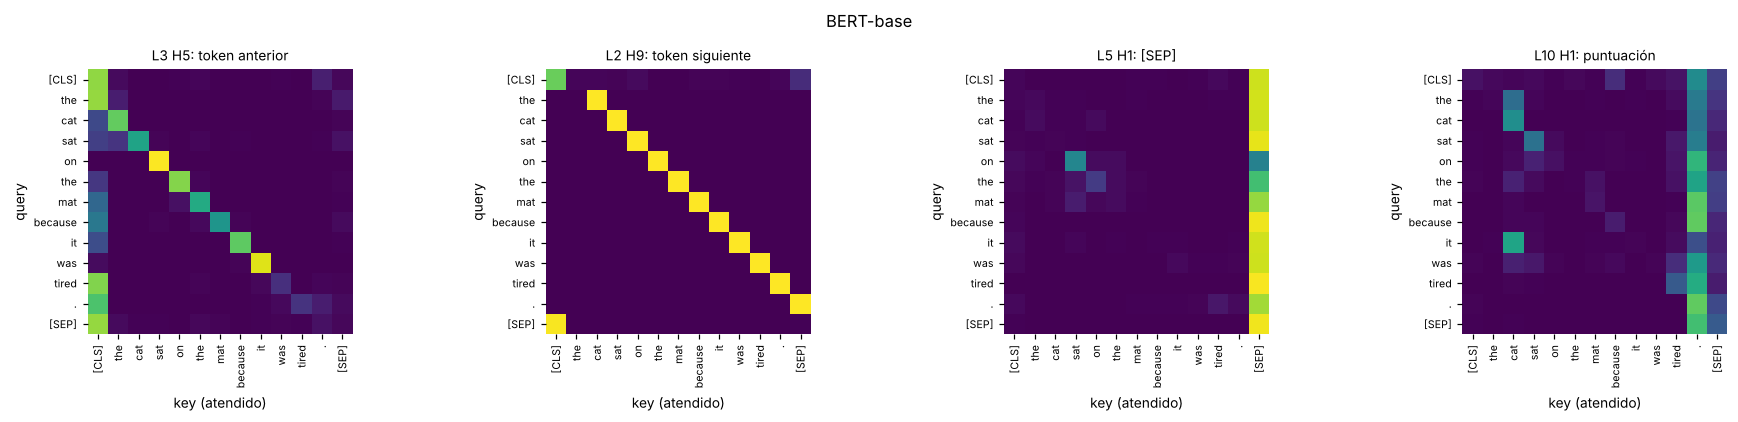

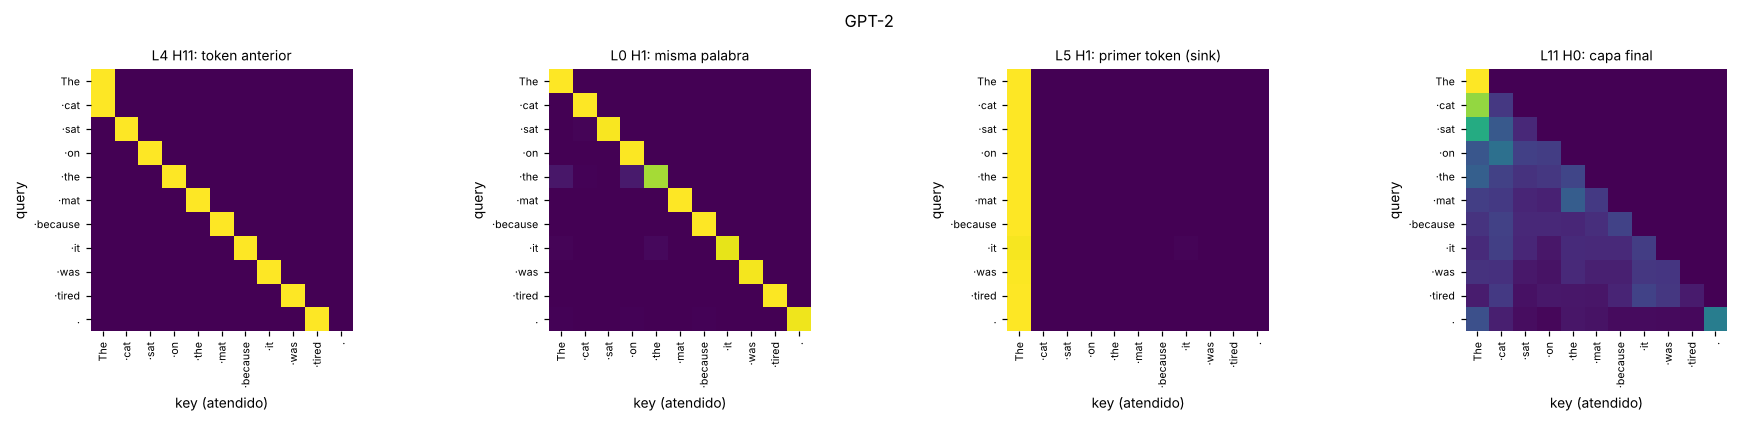

In [10]:
best = lambda key: divmod(ps[key].argmax().item(), 12)
heads_b = [(*best("prev"), "token anterior"), (*best("next"), "token siguiente"),
           (*best("sep"), "[SEP]"), (*best("punct"), "puntuación")]
plot_heads(att_b, toks_b, heads_b, "BERT-base", "figs/bert_heads.png")

ps_g = pattern_scores(att_g, toks_g)
bg = lambda key: divmod(ps_g[key].argmax().item(), 12)
heads_g = [(*bg("prev"), "token anterior"), (*bg("self"), "misma palabra"),
           (*bg("cls"), "primer token (sink)"), (11, 0, "capa final")]
plot_heads(att_g, toks_g, heads_g, "GPT-2", "figs/gpt2_heads.png")

### 4.2 Correferencia: *it* → *animal* vs. *street* en BERT

Top cabezas (capa, cabeza) | tired: animal/street | wide: animal/street
L 6 H10 | 0.284 / 0.067 | 0.012 / 0.590
L 8 H10 | 0.676 / 0.000 | 0.309 / 0.259
L 9 H 8 | 0.454 / 0.003 | 0.023 / 0.045
L 9 H 0 | 0.608 / 0.002 | 0.255 / 0.074
L10 H 8 | 0.564 / 0.001 | 0.245 / 0.078
Cabezas que cumplen ambas condiciones: 22 de 144


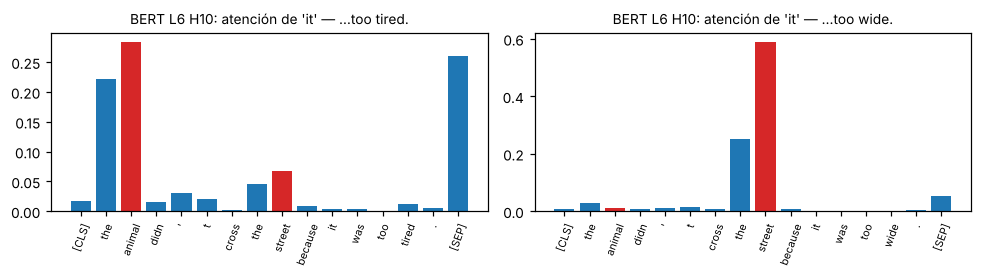

In [11]:
s1 = "The animal didn't cross the street because it was too tired."
s2 = "The animal didn't cross the street because it was too wide."

def it_scores(text):
    att, toks = get_att(bert, tok_bert, text)
    i_it, i_an, i_st = toks.index("it"), toks.index("animal"), toks.index("street")
    return att[:, :, i_it, i_an], att[:, :, i_it, i_st], att, toks

a1, st1, att1, tk1 = it_scores(s1)
a2, st2, att2, tk2 = it_scores(s2)
# Queremos: tired -> it atiende más a animal; wide -> más a street
score = (a1 - st1) + (st2 - a2)
order = score.flatten().argsort(descending=True)[:5]
print("Top cabezas (capa, cabeza) | tired: animal/street | wide: animal/street")
for idx in order:
    l, h = divmod(idx.item(), 12)
    print(f"L{l:2d} H{h:2d} | {a1[l,h]:.3f} / {st1[l,h]:.3f} | {a2[l,h]:.3f} / {st2[l,h]:.3f}")
ok = ((a1 > st1) & (st2 > a2))
print(f"Cabezas que cumplen ambas condiciones: {ok.sum().item()} de 144")

L, Hh = divmod(order[0].item(), 12)
fig, ax = plt.subplots(1, 2, figsize=(9, 2.6))
for axx, att_, tk_, ttl in ((ax[0], att1, tk1, "…too tired."), (ax[1], att2, tk2, "…too wide.")):
    i = tk_.index("it")
    axx.bar(range(len(tk_)), att_[L, Hh, i].numpy(), color=["C3" if t in ("animal", "street") else "C0" for t in tk_])
    axx.set_xticks(range(len(tk_))); axx.set_xticklabels(tk_, rotation=70, fontsize=7)
    axx.set_title(f"BERT L{L} H{Hh}: atención de 'it' — {ttl}", fontsize=9)
plt.tight_layout(); plt.savefig("figs/bert_it.png", bbox_inches="tight"); plt.show()

### 4.3 GPT-2: máscara causal y *attention sinks*

In [12]:
att_g1, toks_g1 = get_att(gpt2, tok_gpt2, s1)
n = att_g1.shape[-1]
upper = att_g1.triu(1)
print("Máximo por encima de la diagonal (todas las capas/cabezas):", upper.abs().max().item())
print("¿Triangular inferior?", torch.allclose(att_g1, att_g1.tril()))

# Proporción de atención que recibe el primer token (promedio sobre cabezas y queries, excluyendo query 0)
first_g = att_g1[:, :, 1:, 0].mean((1, 2)).numpy()
att_b1, toks_b1 = get_att(bert, tok_bert, s1)
first_b = att_b1[:, :, :, 0].mean((1, 2)).numpy()        # [CLS]
sep_b = att_b1[:, :, :, -1].mean((1, 2)).numpy()         # [SEP]
for l in range(12): print(f"capa {l:2d}: GPT-2 primer token={first_g[l]:.2f} | BERT [CLS]={first_b[l]:.2f} [SEP]={sep_b[l]:.2f}")

# Control: ¿es el contenido o la posición? Cambiamos la primera palabra.
att_ctrl, _ = get_att(gpt2, tok_gpt2, "Yesterday the animal didn't cross the street because it was too tired.")
print("Control (otra primera palabra), media capas 2-11:", att_ctrl[2:, :, 1:, 0].mean().item().__round__(3))

Máximo por encima de la diagonal (todas las capas/cabezas): 0.0
¿Triangular inferior? True
capa  0: GPT-2 primer token=0.26 | BERT [CLS]=0.14 [SEP]=0.08
capa  1: GPT-2 primer token=0.45 | BERT [CLS]=0.42 [SEP]=0.09
capa  2: GPT-2 primer token=0.44 | BERT [CLS]=0.38 [SEP]=0.10
capa  3: GPT-2 primer token=0.56 | BERT [CLS]=0.26 [SEP]=0.24
capa  4: GPT-2 primer token=0.60 | BERT [CLS]=0.05 [SEP]=0.55
capa  5: GPT-2 primer token=0.74 | BERT [CLS]=0.04 [SEP]=0.59
capa  6: GPT-2 primer token=0.71 | BERT [CLS]=0.04 [SEP]=0.55
capa  7: GPT-2 primer token=0.81 | BERT [CLS]=0.02 [SEP]=0.54
capa  8: GPT-2 primer token=0.77 | BERT [CLS]=0.03 [SEP]=0.54
capa  9: GPT-2 primer token=0.81 | BERT [CLS]=0.05 [SEP]=0.47
capa 10: GPT-2 primer token=0.85 | BERT [CLS]=0.06 [SEP]=0.09
capa 11: GPT-2 primer token=0.71 | BERT [CLS]=0.04 [SEP]=0.05
Control (otra primera palabra), media capas 2-11: 0.694


### 4.4 Entropía promedio de la atención por capa

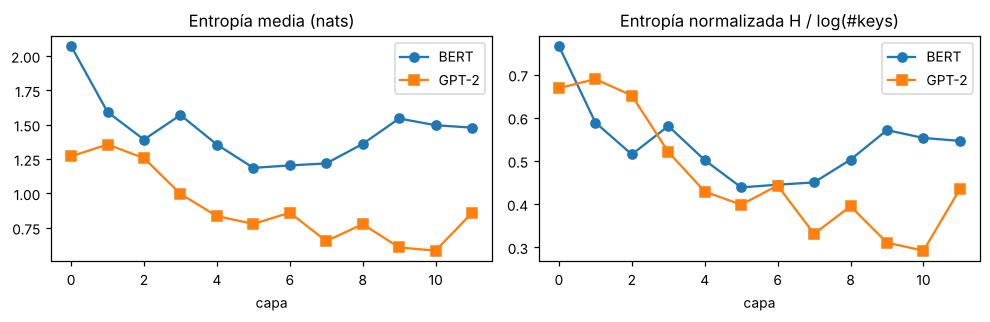

BERT : [2.07 1.59 1.39 1.57 1.36 1.19 1.2  1.22 1.36 1.55 1.5  1.48]
GPT-2: [1.27 1.36 1.26 1.   0.83 0.78 0.86 0.65 0.78 0.61 0.58 0.86]


In [13]:
def entropy_per_layer(att, causal):
    p = att.clamp_min(1e-12)
    H = -(att * p.log()).sum(-1)                            # (L, Hh, n)
    n = att.shape[-1]
    nkeys = torch.arange(1, n + 1).float() if causal else torch.full((n,), float(n))
    Hn = H / nkeys.log().clamp_min(1e-12)                  # normalizada a [0,1]
    sl = slice(1, None) if causal else slice(None)        # query 0 de GPT-2 tiene 1 sola key
    return H[..., sl].mean((1, 2)).numpy(), Hn[..., sl].mean((1, 2)).numpy()

sents = [s1, s2, sent, "Attention mechanisms let every token look at every other token in parallel."]
Eb = np.mean([entropy_per_layer(get_att(bert, tok_bert, s)[0], False) for s in sents], 0)
Eg = np.mean([entropy_per_layer(get_att(gpt2, tok_gpt2, s)[0], True) for s in sents], 0)

fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].plot(Eb[0], "o-", label="BERT"); ax[0].plot(Eg[0], "s-", label="GPT-2")
ax[0].set(title="Entropía media (nats)", xlabel="capa"); ax[0].legend()
ax[1].plot(Eb[1], "o-", label="BERT"); ax[1].plot(Eg[1], "s-", label="GPT-2")
ax[1].set(title="Entropía normalizada H / log(#keys)", xlabel="capa"); ax[1].legend()
plt.tight_layout(); plt.savefig("figs/entropia.png", bbox_inches="tight"); plt.show()
print("BERT :", Eb[0].round(2)); print("GPT-2:", Eg[0].round(2))

### 4.5 (Opcional) bertviz
En un entorno con Jupyter interactivo:

In [14]:
# !pip install bertviz
try:
    from bertviz import head_view
    enc = tok_bert(s1, return_tensors="pt")
    out = bert(**enc)
    head_view(out.attentions, tok_bert.convert_ids_to_tokens(enc["input_ids"][0]))
except ImportError:
    print("bertviz no instalado; ejecutar `pip install bertviz` para la vista interactiva.")

bertviz no instalado; ejecutar `pip install bertviz` para la vista interactiva.


## Conclusiones (resumen)
- La implementación propia coincide con `F.scaled_dot_product_attention` y `nn.MultiheadAttention` (diferencias ~1e-7).
- Var$(q\cdot k)\approx d_k$; sin escalar, la softmax se satura (entropía y gradiente colapsan al crecer $d_k$).
- Tiempo y memoria crecen ~$n^2$; con $n=100{,}000$ la matriz sola ocupa ~37 GiB por cabeza en fp32.
- BERT tiene cabezas posicionales (anterior/siguiente) y cabezas que vuelcan masa en [SEP]/puntuación; GPT-2 es estrictamente triangular inferior y concentra gran parte de la atención en el primer token (*attention sink*) desde las primeras capas.